# MECHA — Exploration du jeu de données (EDA)

Analyse exploratoire du dataset synthétique MECHA utilisé par la solution de maintenance prédictive.

- **Brut** : `data/raw/mecha_dataset_full.csv`, produit par `reference/generate_dataset.py` (avec défauts capteurs injectés).
- **Préparé** : `data/processed/mecha_unified_prepared.csv`, produit par `src/data_preparation.py` (nettoyé + features).

Objectifs : vérifier la cohérence des données avec le contexte MECHA, mesurer leur qualité, comprendre le signal disponible pour les modèles, et justifier les choix de modélisation.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.regles import charger_regles

sns.set_theme(style="whitegrid")
CAPTEURS = ["temperature_C", "vibration_mm_s", "courant_A", "pression_bar", "vitesse_tr_min"]
ETATS = ["normal", "a_risque", "critique", "en_panne"]
COULEURS = {"normal": "#28a745", "a_risque": "#ffc107", "critique": "#fd7e14", "en_panne": "#dc3545"}

brut = pd.read_csv(ROOT / "data/raw/mecha_dataset_full.csv", parse_dates=["timestamp"])
prep = pd.read_csv(ROOT / "data/processed/mecha_unified_prepared.csv", parse_dates=["timestamp"])
print(f"Brut    : {brut.shape[0]:,} lignes x {brut.shape[1]} colonnes")
print(f"Préparé : {prep.shape[0]:,} lignes x {prep.shape[1]} colonnes")

Brut    : 354,162 lignes x 17 colonnes
Préparé : 351,605 lignes x 30 colonnes


## 1. Périmètre : usines, machines, historique

Les sites espagnols, équipés plus récemment, ont un historique plus court (hétérogénéité évoquée lors de l'entretien client).

In [2]:
perimetre = (brut.groupby("usine_id")
             .agg(machines=("machine_id", "nunique"), debut=("timestamp", "min"),
                  fin=("timestamp", "max"), releves=("timestamp", "size"))
             .assign(mois_historique=lambda d: ((d.fin - d.debut).dt.days / 30.4).round(1)))
perimetre

,machines,debut,fin,releves,mois_historique
usine_id,,,,,
USN-ES-01,5,2024-07-01,2025-06-29 23:00:00,43725,11.9
USN-ES-02,4,2024-07-01,2025-06-29 23:00:00,34989,11.9
USN-FR-01,8,2024-01-01,2025-06-29 23:00:00,104921,17.9
USN-FR-02,6,2024-01-01,2025-06-29 23:00:00,78703,17.9
USN-FR-03,7,2024-01-01,2025-06-29 23:00:00,91824,17.9


In [3]:
brut.groupby("type_machine")["machine_id"].nunique().rename("machines").to_frame()

,machines
type_machine,
CNC-Fraisage,10
CNC-Tournage,10
Centre-Usinage,3
Découpe-Laser,7


## 2. Qualité des données brutes

Le fichier brut contient des défauts typiques d'un parc IoT : valeurs manquantes, pertes de transmission, capteurs figés, valeurs hors limites physiques, doublons.

In [4]:
bornes = charger_regles()["capteurs"]
pays = brut["usine_id"].str[4:6]
qualite = pd.DataFrame({
    "manquantes (%) FR": brut.loc[pays == "FR", CAPTEURS].isna().mean() * 100,
    "manquantes (%) ES": brut.loc[pays == "ES", CAPTEURS].isna().mean() * 100,
    "hors bornes": [int(((brut[c] < bornes[c]["min"]) | (brut[c] > bornes[c]["max"])).sum()) for c in CAPTEURS],
}).round(2)
print("Doublons (machine, horodatage) :", int(brut.duplicated(["machine_id", "timestamp"]).sum()))
qualite

Doublons (machine, horodatage) : 354


,manquantes (%) FR,manquantes (%) ES,hors bornes
temperature_C,0.70,1.50,176
vibration_mm_s,0.73,1.44,155
courant_A,0.71,1.39,179
pression_bar,0.73,1.41,152
vitesse_tr_min,0.73,1.45,168


In [5]:
rapport = json.loads((ROOT / "data/processed/rapport_qualite.json").read_text(encoding="utf-8"))
pd.Series(rapport, name="valeur").to_frame()

,valeur
lignes_brutes,354162
doublons_supprimes,354
valeurs_manquantes_brutes,15553
valeurs_hors_bornes,829
valeurs_capteur_fige,1610
valeurs_imputees,13574
lignes_ecartees,2203
lignes_nettoyees,351605


Le nettoyage (`src/data_preparation.py`, paramétré par `config/regles_metier.yaml`) récupère la quasi-totalité des relevés : moins de 1 % des lignes sont écartées.

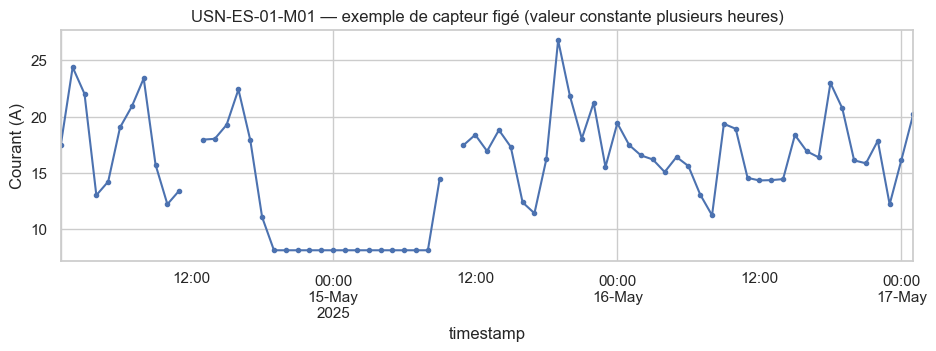

In [6]:
m = brut["machine_id"].iloc[0]
serie = brut[brut.machine_id == m].set_index("timestamp")["courant_A"]
debut = serie.index[serie.diff().eq(0).rolling(6).sum().eq(6).fillna(False).to_numpy().argmax()] - pd.Timedelta(hours=24)
fenetre = serie[debut: debut + pd.Timedelta(hours=72)]
ax = fenetre.plot(figsize=(11, 3), marker=".", title=f"{m} — exemple de capteur figé (valeur constante plusieurs heures)")
ax.set_ylabel("Courant (A)");

## 3. Déséquilibre des classes

Les pannes sont rares. Un modèle qui répondrait toujours « pas de panne » obtiendrait déjà une accuracy très élevée : d'où l'évaluation complémentaire sur un test rééquilibré 50/50 (consigne de l'encadrant).

Relevés en panne              : 2.45%
Relevés à moins de 24 h d'une panne : 2.32%
Accuracy d'un modèle naïf (toujours 0) sur panne_dans_24h : 97.7%


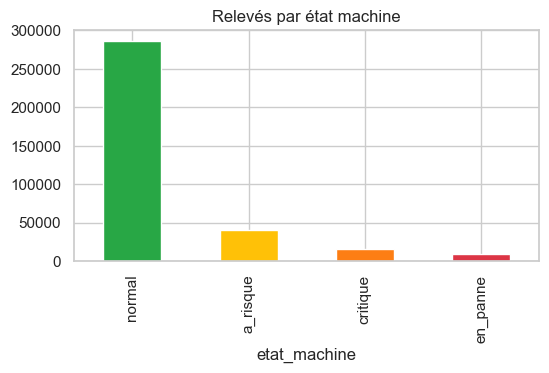

In [7]:
taux = prep[["en_panne", "panne_dans_24h"]].mean()
print(f"Relevés en panne              : {taux['en_panne']:.2%}")
print(f"Relevés à moins de 24 h d'une panne : {taux['panne_dans_24h']:.2%}")
print(f"Accuracy d'un modèle naïf (toujours 0) sur panne_dans_24h : {1 - taux['panne_dans_24h']:.1%}")
prep["etat_machine"].value_counts().reindex(ETATS).plot.bar(color=[COULEURS[e] for e in ETATS], figsize=(6, 3),
                                                          title="Relevés par état machine");

## 4. Capteurs selon l'état de la machine

Le signal existe (températures et courants plus élevés, pression et vitesse plus basses quand la panne approche) mais les distributions se chevauchent fortement à cause du bruit capteur : une mesure isolée ne suffit pas à trancher.

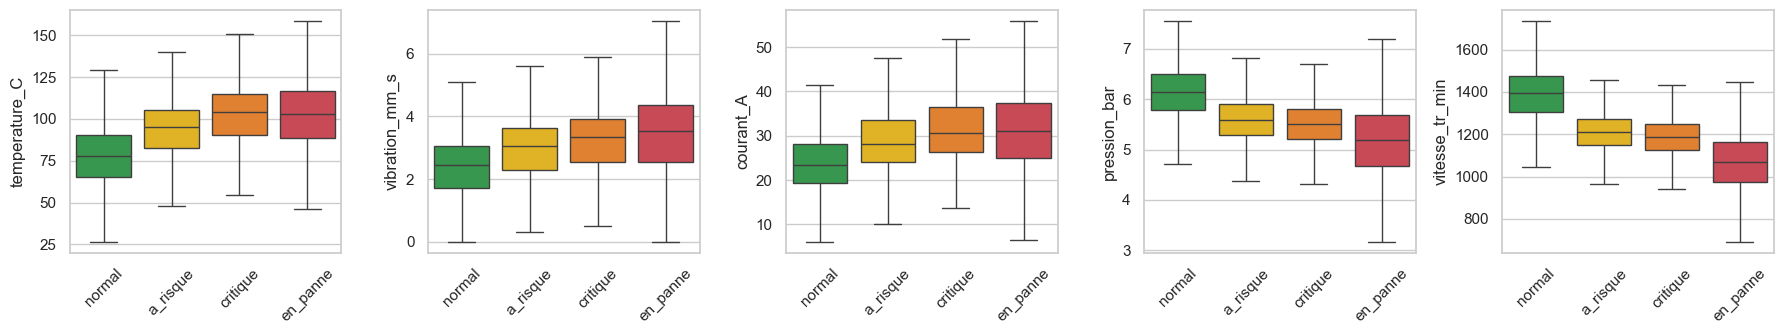

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, c in zip(axes, CAPTEURS):
    sns.boxplot(data=prep, x="etat_machine", y=c, order=ETATS, palette=COULEURS, hue="etat_machine",
                legend=False, ax=ax, showfliers=False)
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
fig.tight_layout()

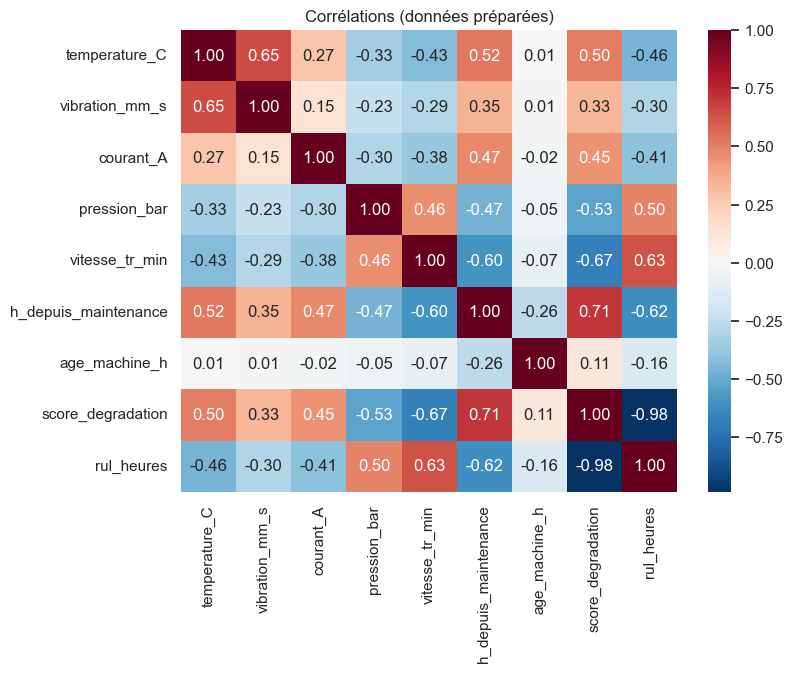

In [9]:
corr = prep[CAPTEURS + ["h_depuis_maintenance", "age_machine_h", "score_degradation", "rul_heures"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Corrélations (données préparées)");

`h_depuis_maintenance` est très corrélé au RUL : dans la simulation, chaque panne est suivie d'une maintenance corrective qui remet ce compteur à zéro. C'est pourquoi une régression linéaire fait jeu égal avec les arbres sur le RUL (voir `models/training_results.json`).

## 5. Dynamique avant une panne

La dégradation est progressive sur plusieurs jours. Avec la seule mesure instantanée, distinguer « panne dans 24 h » de « panne dans 3 à 7 jours » est difficile : c'est ce qu'explique la validation de la règle d'alerte (la plupart des alertes précèdent une panne de quelques jours plutôt que de 24 h).

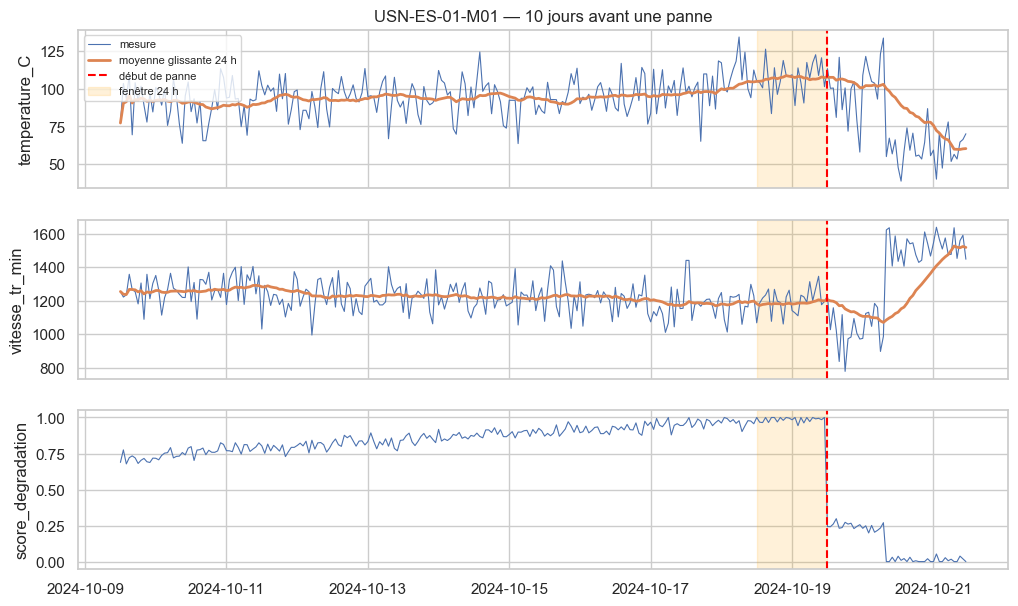

In [10]:
g = prep[prep.machine_id == prep.machine_id.iloc[0]].reset_index(drop=True)
debuts = g.index[(g.en_panne == 1) & (g.en_panne.shift(fill_value=0) == 0)]
d = debuts[2]
fen = g.iloc[d - 24 * 10: d + 48]
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, c in zip(axes, ["temperature_C", "vitesse_tr_min", "score_degradation"]):
    ax.plot(fen.timestamp, fen[c], lw=0.8, label="mesure")
    if c != "score_degradation":
        ax.plot(fen.timestamp, fen[c].rolling(24, min_periods=1).mean(), lw=2, label="moyenne glissante 24 h")
    ax.axvline(g.timestamp[d], color="red", ls="--", label="début de panne")
    ax.axvspan(g.timestamp[d] - pd.Timedelta(hours=24), g.timestamp[d], color="orange", alpha=0.15, label="fenêtre 24 h")
    ax.set_ylabel(c)
axes[0].legend(loc="upper left", fontsize=8)
axes[0].set_title(f"{g.machine_id[0]} — 10 jours avant une panne");

La moyenne glissante 24 h fait nettement ressortir la tendance : c'est le principal levier d'amélioration identifié (features temporelles calculées sur l'historique stocké en base).

## 6. Fréquence des pannes et âge des machines

count    30.0
mean      8.6
std       1.5
min       6.0
25%       7.2
50%       8.8
75%       9.9
max      11.4
Name: pannes_par_an, dtype: float64

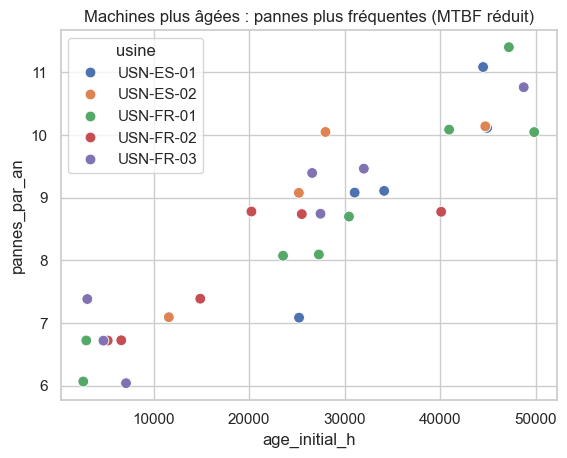

In [11]:
pannes = (prep.groupby("machine_id")
          .agg(pannes=("nb_pannes_total", "max"), age_initial_h=("age_machine_h", "min"),
               heures=("timestamp", "size"), usine=("usine_id", "first")))
pannes["pannes_par_an"] = pannes.pannes / pannes.heures * 8760
ax = sns.scatterplot(data=pannes, x="age_initial_h", y="pannes_par_an", hue="usine", s=60)
ax.set_title("Machines plus âgées : pannes plus fréquentes (MTBF réduit)");
pannes.pannes_par_an.describe().round(1)

## 7. Conclusions pour la modélisation

1. **Données** : 30 machines, 5 usines, historique de 12 à 18 mois, ~2,5 % de relevés en panne. Le nettoyage conserve plus de 99 % des relevés.
2. **Déséquilibre** : l'accuracy seule est trompeuse → évaluation sur test 50/50 (le modèle reconnaît-il une panne ?) **et** sur la distribution réelle (combien de fausses alertes ?).
3. **Signal** : réel mais bruité sur une mesure instantanée ; la dégradation se lit mieux sur une tendance → alerte déclenchée sur plusieurs relevés consécutifs, et features temporelles comme piste d'amélioration.
4. **RUL** : dominé par `h_depuis_maintenance` → évaluation en split temporel, à comparer à une régression linéaire ; à utiliser comme ordre de grandeur.
5. **Hétérogénéité** : les sites espagnols ont moins d'historique et plus de pertes de mesure → à suivre lors du déploiement progressif.